In [13]:
import torch
from PIL import Image
from transformers import Sam3Processor, Sam3Model

import matplotlib.pyplot as plt
import numpy as np
import colorsys

In [8]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [9]:
model = Sam3Model.from_pretrained("facebook/sam3").to(device)
processor = Sam3Processor.from_pretrained("facebook/sam3")

Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]

In [10]:
img_path = "../data/test-penguin.jpeg"

In [19]:
image = Image.open(img_path).convert("RGB")

inputs = processor(images=image, text="penguin", return_tensors="pt").to(model.device)

with torch.no_grad():
    outputs = model(**inputs)

In [20]:
results = processor.post_process_instance_segmentation(
    outputs,
    threshold=0.5,
    mask_threshold=0.5,
    target_sizes=inputs.get("original_sizes").tolist(),
)[0]

%time

CPU times: user 2 μs, sys: 3 μs, total: 5 μs
Wall time: 5.01 μs


In [21]:
masks, boxes, scores = results["masks"], results["boxes"], results["scores"]

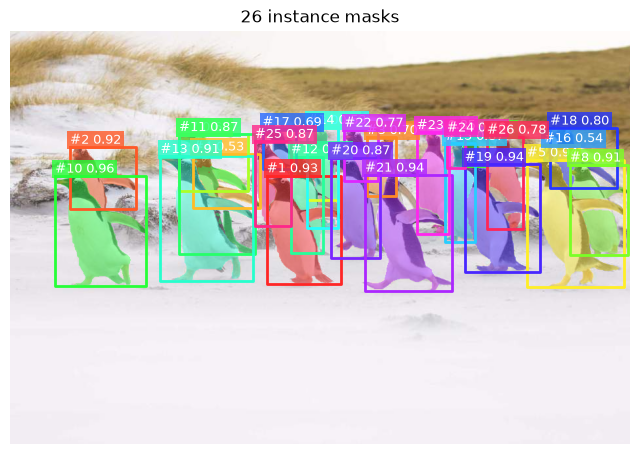

In [22]:
img = np.array(image)
n = len(results["masks"])
def instance_color(i, n):
    r, g, b = colorsys.hsv_to_rgb(i / max(n, 1), 0.85, 1.0)
    return np.array([r, g, b])
overlay = img.astype(np.float32) / 255.0
alpha = 0.45
plt.figure(figsize=(8, 8))
for i, (mask, box, score) in enumerate(
    zip(results["masks"], results["boxes"], results["scores"])
):
    m = mask.cpu().numpy() if hasattr(mask, "cpu") else np.asarray(mask)
    m = m > 0.5
    color = instance_color(i, n)
    overlay[m] = (1 - alpha) * overlay[m] + alpha * color
    x1, y1, x2, y2 = [float(v) for v in box]
    plt.plot([x1, x2, x2, x1, x1], [y1, y1, y2, y2, y1], color=color, linewidth=2)
    plt.text(
        x1, max(0, y1 - 5), f"#{i+1} {float(score):.2f}",
        color="white", fontsize=9,
        bbox=dict(facecolor=color, alpha=0.8, pad=2, edgecolor="none"),
    )
plt.imshow(np.clip(overlay, 0, 1))
plt.axis("off")
plt.title(f"{n} instance masks")
plt.show()

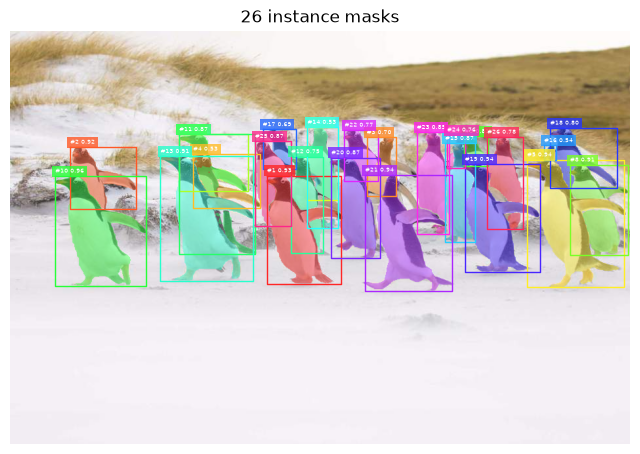

In [23]:
img = np.array(image)
n = len(results["masks"])
def instance_color(i, n):
    r, g, b = colorsys.hsv_to_rgb(i / max(n, 1), 0.85, 1.0)
    return np.array([r, g, b])
overlay = img.astype(np.float32) / 255.0
alpha = 0.45
plt.figure(figsize=(8, 8))
for i, (mask, box, score) in enumerate(
    zip(results["masks"], results["boxes"], results["scores"])
):
    m = mask.cpu().numpy() if hasattr(mask, "cpu") else np.asarray(mask)
    m = m > 0.5
    color = instance_color(i, n)
    overlay[m] = (1 - alpha) * overlay[m] + alpha * color
    x1, y1, x2, y2 = [float(v) for v in box]
    plt.plot([x1, x2, x2, x1, x1], [y1, y1, y2, y2, y1], color=color, linewidth=1)
    plt.text(
        x1, max(0, y1 - 5), f"#{i+1} {float(score):.2f}",
        color="white", fontsize=4,
        bbox=dict(facecolor=color, alpha=0.8, pad=2, edgecolor="none"),
    )
plt.imshow(np.clip(overlay, 0, 1))
plt.axis("off")
plt.title(f"{n} instance masks")
plt.show()